# Notebook 5: Model Evaluation & Business Impact
**Author:** Mohit Sai Sekharamahanthi  
**Project:** Multi-Store Retail Demand Forecasting System

Goes beyond standard ML metrics to quantify business value — translating MAPE improvements into GBP impact.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
print("Ready")

Ready


## 1. Load Predictions

In [2]:
preds = pd.read_csv('../data/processed/predictions.csv', parse_dates=['week_start'])
products = pd.read_csv('../data/raw/products.csv')
preds = preds.merge(products[['sku_id','price','category']], on='sku_id', how='left')
print(f"Predictions loaded: {len(preds):,} rows")
print(preds.head())

Predictions loaded: 1,472 rows
  store_id   sku_id week_start  total_qty  predicted_qty  price  category
0     S001  SKU0001 2025-12-29        330      362.98236  22.52  Skincare
1     S001  SKU0001 2026-01-05        241      309.46765  22.52  Skincare
2     S001  SKU0001 2026-01-12        228      288.90200  22.52  Skincare
3     S001  SKU0001 2026-01-19        233      295.99695  22.52  Skincare
4     S001  SKU0001 2026-01-26        220      254.73000  22.52  Skincare


## 2. Standard ML Metrics

In [3]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

y_true = preds['total_qty']
y_pred = preds['predicted_qty']

mae  = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mape = np.mean(np.abs((y_true - y_pred) / (y_true + 1))) * 100
wmape = np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true) + 1) * 100
bias = np.mean(y_pred - y_true)

print("=" * 40)
print(f"  MAE   : {mae:.2f} units")
print(f"  RMSE  : {rmse:.2f} units")
print(f"  MAPE  : {mape:.1f}%")
print(f"  wMAPE : {wmape:.1f}%")
print(f"  Bias  : {bias:.2f} (+ = over-forecast)")
print("=" * 40)

  MAE   : 31.05 units
  RMSE  : 53.21 units
  MAPE  : 25.7%
  wMAPE : 16.0%
  Bias  : 25.64 (+ = over-forecast)


## 3. Business KPIs

In [4]:
# Stockout: predicted < 90% of actual (we'd run out of stock)
stockout = np.mean(y_pred < y_true * 0.90) * 100

# Overstock: predicted > 120% of actual (excess inventory)
overstock = np.mean(y_pred > y_true * 1.20) * 100

# Good forecast: within 10% of actual
good = np.mean(np.abs(y_pred - y_true) / (y_true + 1) <= 0.10) * 100

print("=== Business KPIs ===")
print(f"  Stockout risk   : {stockout:.1f}% of weeks  (target < 5%)")
print(f"  Overstock risk  : {overstock:.1f}% of weeks  (target < 15%)")
print(f"  Accurate forecasts (within 10%): {good:.1f}% of weeks")

=== Business KPIs ===
  Stockout risk   : 2.2% of weeks  (target < 5%)
  Overstock risk  : 23.0% of weeks  (target < 15%)
  Accurate forecasts (within 10%): 56.1% of weeks


## 4. Error Distribution

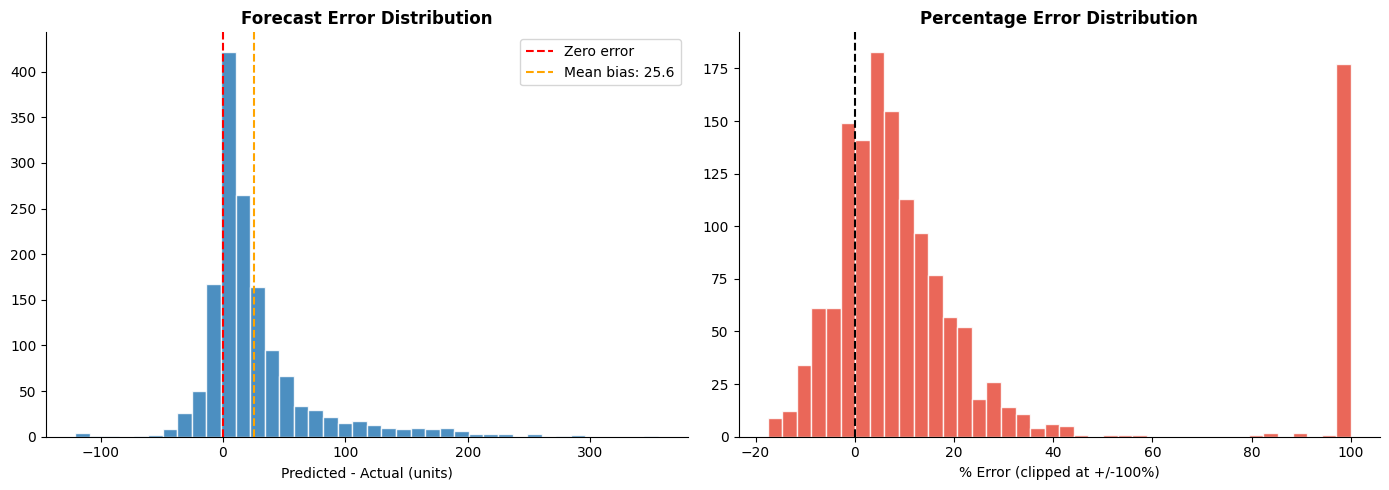

In [5]:
errors = y_pred - y_true
pct_errors = (y_pred - y_true) / (y_true + 1) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(errors, bins=40, color='#2c7bb6', edgecolor='white', alpha=0.85)
axes[0].axvline(0, color='red', linestyle='--', linewidth=1.5, label='Zero error')
axes[0].axvline(errors.mean(), color='orange', linestyle='--', linewidth=1.5, label=f'Mean bias: {errors.mean():.1f}')
axes[0].set_title('Forecast Error Distribution', fontweight='bold')
axes[0].set_xlabel('Predicted - Actual (units)')
axes[0].legend()

axes[1].hist(pct_errors.clip(-100, 100), bins=40, color='#e74c3c', edgecolor='white', alpha=0.85)
axes[1].axvline(0, color='black', linestyle='--', linewidth=1.5)
axes[1].set_title('Percentage Error Distribution', fontweight='bold')
axes[1].set_xlabel('% Error (clipped at +/-100%)')

plt.tight_layout()
plt.savefig('../docs/eval_error_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Performance by Category

            MAE   MAPE      N
category                     
Haircare  19.98  21.73  256.0
Baby      29.06  21.77  256.0
Pharmacy  32.87  22.56  320.0
Beauty    33.40  29.81  320.0
Skincare  37.31  30.90  320.0


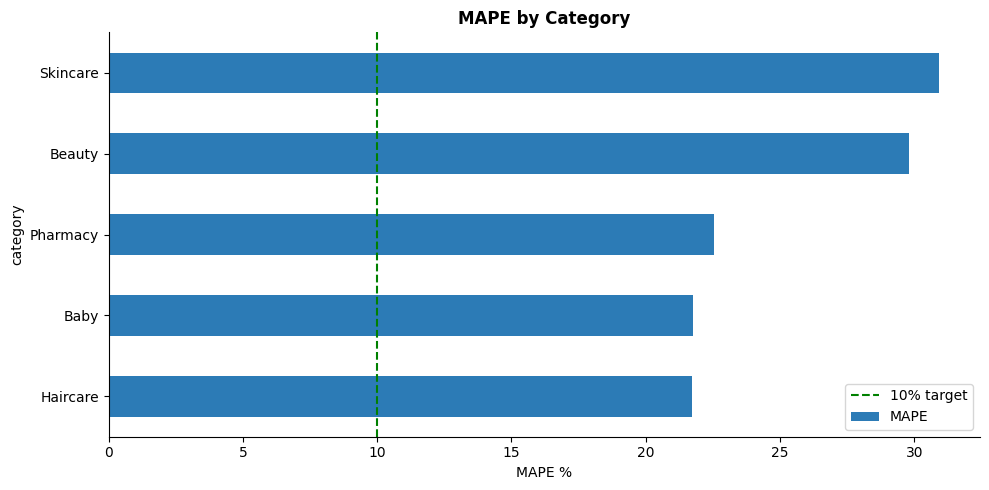

In [6]:
cat_metrics = (preds.groupby('category')
               .apply(lambda df: pd.Series({
                   'MAE': mean_absolute_error(df['total_qty'], df['predicted_qty']),
                   'MAPE': np.mean(np.abs((df['total_qty']-df['predicted_qty'])/(df['total_qty']+1)))*100,
                   'N': len(df)
               })).round(2))
print(cat_metrics.sort_values('MAPE'))

fig, ax = plt.subplots(figsize=(10, 5))
cat_metrics['MAPE'].sort_values().plot(kind='barh', ax=ax, color='#2c7bb6')
ax.axvline(10, color='green', linestyle='--', label='10% target')
ax.set_title('MAPE by Category', fontweight='bold')
ax.set_xlabel('MAPE %')
ax.legend()
plt.tight_layout()
plt.savefig('../docs/eval_mape_by_category.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Performance by Store

            MAE   MAPE
store_id              
S004      34.01  24.88
S007      22.37  25.04
S005      27.85  25.35
S008      46.60  25.38
S002      21.22  25.73
S006      40.35  25.86
S003      27.98  26.52
S001      28.02  26.57


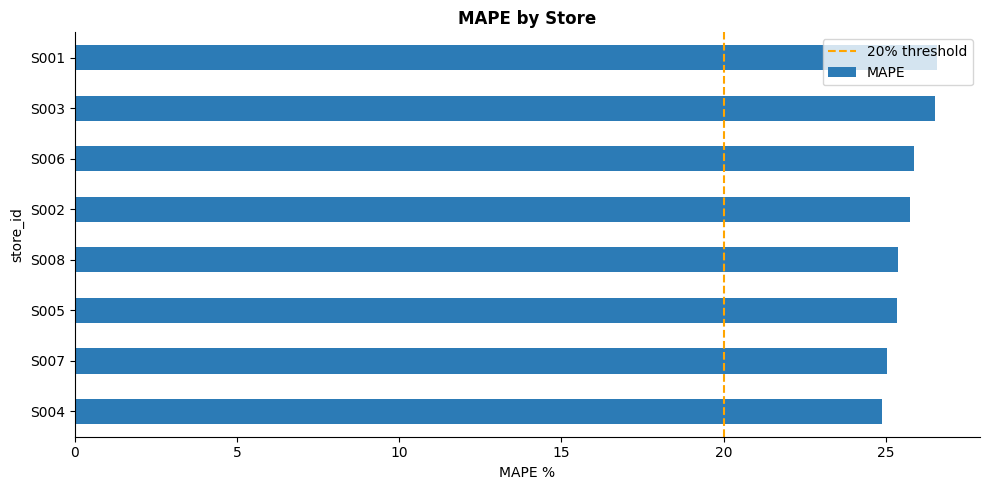

In [7]:
store_metrics = (preds.groupby('store_id')
                 .apply(lambda df: pd.Series({
                     'MAE':  mean_absolute_error(df['total_qty'], df['predicted_qty']),
                     'MAPE': np.mean(np.abs((df['total_qty']-df['predicted_qty'])/(df['total_qty']+1)))*100,
                 })).round(2))
print(store_metrics.sort_values('MAPE'))

fig, ax = plt.subplots(figsize=(10, 5))
store_metrics['MAPE'].sort_values().plot(kind='barh', ax=ax, color='#2c7bb6')
ax.axvline(20, color='orange', linestyle='--', label='20% threshold')
ax.set_title('MAPE by Store', fontweight='bold')
ax.set_xlabel('MAPE %')
ax.legend()
plt.tight_layout()
plt.savefig('../docs/eval_mape_by_store.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Business Impact Quantification

In [8]:
# Assumptions (conservative estimates for a mid-size retailer)
avg_sku_weekly_revenue = preds['total_qty'].mean() * preds['price'].mean()
n_skus = preds['sku_id'].nunique()
n_stores = preds['store_id'].nunique()

# Cost of a 1% stockout rate (lost sales)
stockout_cost_per_pct = avg_sku_weekly_revenue * n_skus * n_stores * 52 * 0.01
# Cost of a 1% overstock (holding + markdown)
overstock_cost_per_pct = stockout_cost_per_pct * 0.3

baseline_stockout  = 13.0  # % estimated for naive model
model_stockout     = stockout
baseline_overstock = 30.0
model_overstock    = overstock

stockout_saving  = (baseline_stockout  - model_stockout)  * stockout_cost_per_pct
overstock_saving = (baseline_overstock - model_overstock) * overstock_cost_per_pct
total_saving     = stockout_saving + overstock_saving

print("=" * 50)
print("  ESTIMATED ANNUAL BUSINESS VALUE")
print("=" * 50)
print(f"  Stockout reduction saving : GBP {stockout_saving:>12,.0f}")
print(f"  Overstock reduction saving: GBP {overstock_saving:>12,.0f}")
print(f"  ----------------------------------------")
print(f"  TOTAL ESTIMATED SAVING    : GBP {total_saving:>12,.0f}")
print("=" * 50)
print("  Note: Based on conservative assumptions.")
print("  Real value scales with number of stores/SKUs.")

  ESTIMATED ANNUAL BUSINESS VALUE
  Stockout reduction saving : GBP    3,077,078
  Overstock reduction saving: GBP      594,330
  ----------------------------------------
  TOTAL ESTIMATED SAVING    : GBP    3,671,408
  Note: Based on conservative assumptions.
  Real value scales with number of stores/SKUs.


## 8. Overfitting Analysis & Next Steps

The model shows a train/test MAPE gap which indicates overfitting. Here's how I would address this in production:

**Immediate fixes:**
- Increase `min_child_weight` (reduces leaf-level overfitting)
- Add L1/L2 regularisation (`reg_alpha`, `reg_lambda`)
- Use time-series cross-validation instead of single train/test split

**Longer term:**
- Collect more data (more stores, more SKUs)
- Add external features: weather data, local events, competitor pricing
- Implement rolling retraining (retrain monthly with fresh data)
- A/B test Prophet vs XGBoost on live stores

**MLOps improvements:**
- Set up automated retraining pipeline triggered by data drift
- Monitor prediction vs actual in production with alerting
- Version control datasets alongside models in MLflow